In [1]:
# Via Deepseek

In [3]:
# Cell 1 — Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.stats import pearsonr, spearmanr

from statsmodels.tsa.stattools import adfuller, ccf, grangercausalitytests
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["figure.figsize"] = (12, 5)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)

RANDOM_STATE = 42

In [4]:
# Cell 2 — Load data
FILE_PATH = r"D:\miniproject\data\bronze\delhi_air_weather.csv"
df = pd.read_csv(FILE_PATH, parse_dates=["timestamp"])
print(df.shape)
df.head()

(131400, 40)


,timestamp,PM2.5 (µg/m³),PM10 (µg/m³),NO (µg/m³),NO2 (µg/m³),NOx (ppb),NH3 (µg/m³),SO2 (µg/m³),CO (mg/m³),Ozone (µg/m³),Benzene (µg/m³),Toluene (µg/m³),Xylene (µg/m³),O Xylene (µg/m³),Eth-Benzene (µg/m³),MP-Xylene (µg/m³),AT (°C),RH (%),WS (m/s),WD (deg),RF (mm),TOT-RF (mm),SR (W/mt2),BP (mmHg),VWS (m/s),station_name,latitude_x,longitude_x,temperature_2m,relative_humidity_2m,wind_speed_10m,wind_direction_10m,precipitation,rain,surface_pressure,boundary_layer_height,wind_u,wind_v,latitude_y,longitude_y
0,2025-01-01 00:00:00,200.41,424.39,137.17,NaN,98.82,NaN,NaN,1.51,2.75,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,Lodhi Road,28.5918,77.2273,10.0,94,1.81,354,0.0,0.0,994.7,75.0,0.189197,-1.800085,28.5918,77.2273
1,2025-01-01 01:00:00,253.74,427.31,153.96,NaN,108.86,NaN,NaN,1.53,4.49,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,Lodhi Road,28.5918,77.2273,9.2,94,1.83,349,0.0,0.0,994.3,85.0,0.349180,-1.796378,28.5918,77.2273
2,2025-01-01 02:00:00,241.08,423.43,157.01,NaN,111.50,NaN,NaN,1.52,3.99,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,Lodhi Road,28.5918,77.2273,9.4,94,1.90,342,0.0,0.0,994.0,95.0,0.587132,-1.807007,28.5918,77.2273
3,2025-01-01 03:00:00,153.84,391.40,123.85,NaN,91.58,NaN,NaN,1.09,2.27,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,Lodhi Road,28.5918,77.2273,10.2,93,1.25,344,0.0,0.0,994.3,45.0,0.344547,-1.201577,28.5918,77.2273
4,2025-01-01 04:00:00,86.06,289.40,83.12,1.86,66.96,NaN,NaN,0.74,2.64,0.0,0.0,0.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.0,NaN,NaN,NaN,Lodhi Road,28.5918,77.2273,10.0,93,1.03,321,0.0,0.0,993.9,45.0,0.648200,-0.800460,28.5918,77.2273


In [32]:
# --- Cell 3: structure + duplicate check (fixed) ---
df.info()
print("\nTimestamp range:", df["timestamp"].min(), "→", df["timestamp"].max())
print("Stations:", df["station_name"].nunique())

# Option A — per-station duplicate count (equivalent to what you wanted)
dup_per_station = (
    df.groupby("station_name")["timestamp"]
      .apply(lambda s: s.duplicated().sum())
      .sort_values(ascending=False)
)
print("\nDuplicate timestamps per station:\n", dup_per_station)

# Option B — one-liner for the whole frame (usually what you actually need)
print("\nTotal duplicated (station, timestamp) rows:",
      df.duplicated(subset=["station_name", "timestamp"]).sum())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131400 entries, 0 to 131399
Data columns (total 40 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   timestamp              131400 non-null  datetime64[ns]
 1   PM2.5 (µg/m³)          124519 non-null  float64       
 2   PM10 (µg/m³)           124022 non-null  float64       
 3   NO (µg/m³)             126451 non-null  float64       
 4   NO2 (µg/m³)            125684 non-null  float64       
 5   NOx (ppb)              126898 non-null  float64       
 6   NH3 (µg/m³)            119092 non-null  float64       
 7   SO2 (µg/m³)            117398 non-null  float64       
 8   CO (mg/m³)             126278 non-null  float64       
 9   Ozone (µg/m³)          125759 non-null  float64       
 10  Benzene (µg/m³)        112370 non-null  float64       
 11  Toluene (µg/m³)        95900 non-null   float64       
 12  Xylene (µg/m³)         2160 non-null    floa

In [6]:
# Cell 4 — Missing % sorted
miss = (df.isnull().mean() * 100).round(2).sort_values(ascending=False)
print(miss)

O Xylene (µg/m³)         100.00
Xylene (µg/m³)            98.36
MP-Xylene (µg/m³)         85.05
Eth-Benzene (µg/m³)       84.44
VWS (m/s)                 80.48
RF (mm)                   40.91
BP (mmHg)                 35.08
AT (°C)                   28.15
Toluene (µg/m³)           27.02
WS (m/s)                  24.38
SR (W/mt2)                18.41
WD (deg)                  15.68
RH (%)                    15.65
Benzene (µg/m³)           14.48
TOT-RF (mm)               13.33
SO2 (µg/m³)               10.66
NH3 (µg/m³)                9.37
PM10 (µg/m³)               5.61
PM2.5 (µg/m³)              5.24
NO2 (µg/m³)                4.35
Ozone (µg/m³)              4.29
CO (mg/m³)                 3.90
NO (µg/m³)                 3.77
NOx (ppb)                  3.43
timestamp                  0.00
station_name               0.00
latitude_x                 0.00
longitude_x                0.00
temperature_2m             0.00
relative_humidity_2m       0.00
wind_speed_10m             0.00
wind_dir

In [7]:
# Cell 5 — Drop columns with > 10% missing
MISS_THRESHOLD = 10
cols_over_10 = miss[miss > MISS_THRESHOLD].index.tolist()
print(f"Dropping {len(cols_over_10)} columns (> {MISS_THRESHOLD}% missing):")
print(cols_over_10)

df1 = df.drop(columns=cols_over_10).copy()

Dropping 16 columns (> 10% missing):
['O Xylene (µg/m³)', 'Xylene (µg/m³)', 'MP-Xylene (µg/m³)', 'Eth-Benzene (µg/m³)', 'VWS (m/s)', 'RF (mm)', 'BP (mmHg)', 'AT (°C)', 'Toluene (µg/m³)', 'WS (m/s)', 'SR (W/mt2)', 'WD (deg)', 'RH (%)', 'Benzene (µg/m³)', 'TOT-RF (mm)', 'SO2 (µg/m³)']


In [8]:
# Cell 6 — Drop redundant cols + report
df1.drop(columns=["NOx (ppb)", "precipitation"], inplace=True)
print(f"Final shape: {df1.shape}")
df1.info()

Final shape: (131400, 22)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 131400 entries, 0 to 131399
Data columns (total 22 columns):
 #   Column                 Non-Null Count   Dtype         
---  ------                 --------------   -----         
 0   timestamp              131400 non-null  datetime64[ns]
 1   PM2.5 (µg/m³)          124519 non-null  float64       
 2   PM10 (µg/m³)           124022 non-null  float64       
 3   NO (µg/m³)             126451 non-null  float64       
 4   NO2 (µg/m³)            125684 non-null  float64       
 5   NH3 (µg/m³)            119092 non-null  float64       
 6   CO (mg/m³)             126278 non-null  float64       
 7   Ozone (µg/m³)          125759 non-null  float64       
 8   station_name           131400 non-null  object        
 9   latitude_x             131400 non-null  float64       
 10  longitude_x            131400 non-null  float64       
 11  temperature_2m         131400 non-null  float64       
 12  relative_humidity_

In [9]:
# Cell 7 — Feature groups
POLLUTANTS = ["PM2.5 (µg/m³)", "PM10 (µg/m³)", "NO (µg/m³)", "NO2 (µg/m³)",
              "NH3 (µg/m³)", "CO (mg/m³)", "Ozone (µg/m³)"]
METEO = ["temperature_2m", "relative_humidity_2m", "wind_speed_10m",
         "wind_direction_10m", "rain", "surface_pressure",
         "boundary_layer_height", "wind_u", "wind_v"]

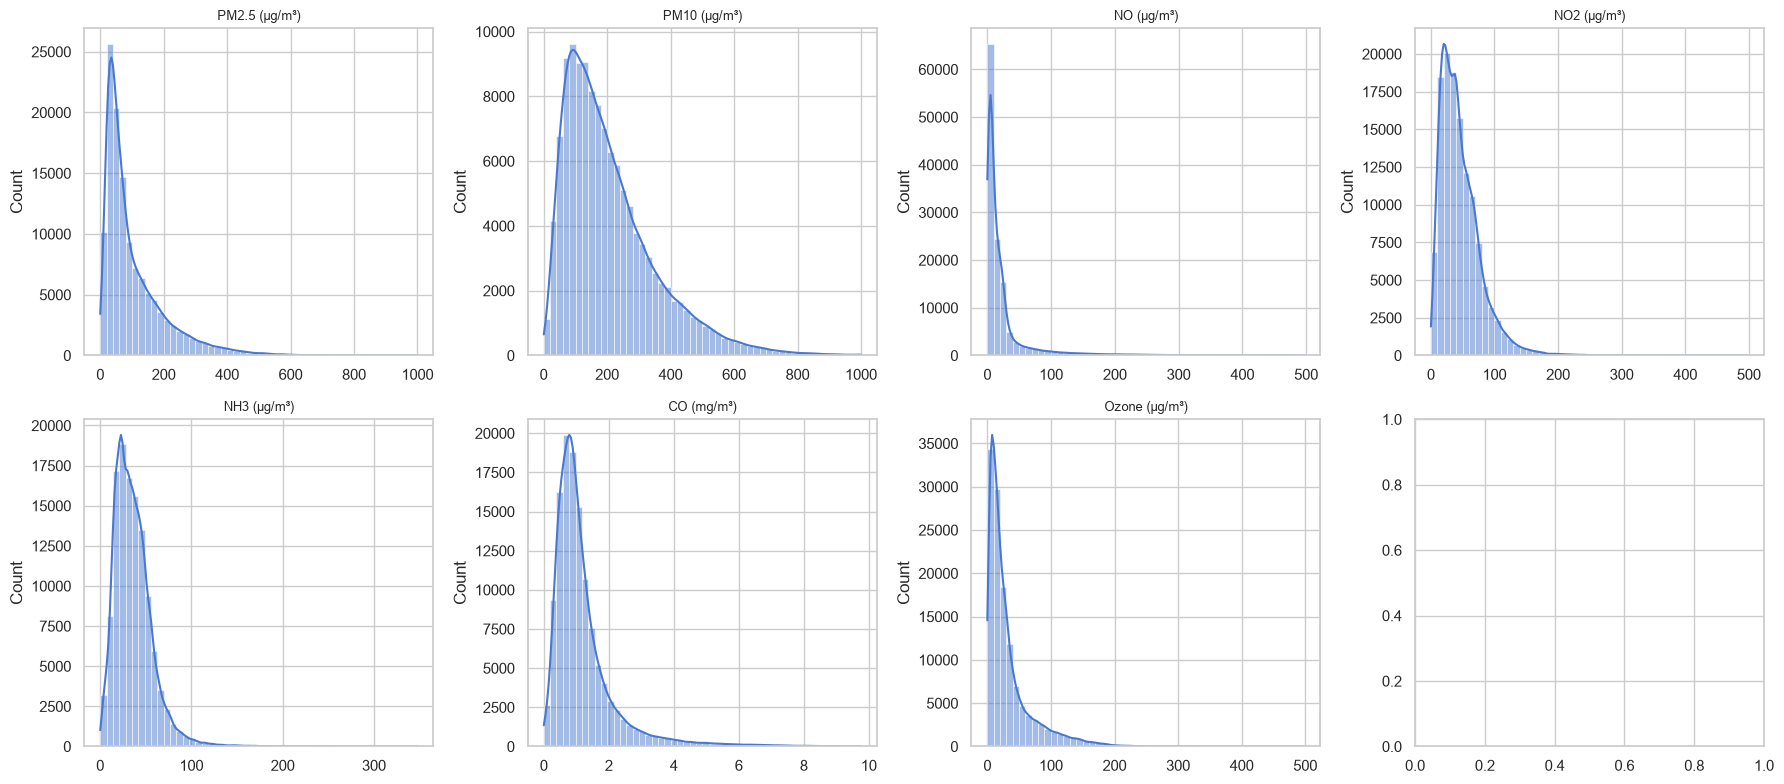

In [10]:
# Cell 8 — Distribution overview
fig, axes = plt.subplots(2, 4, figsize=(18, 8))
for ax, col in zip(axes.flatten(), POLLUTANTS):
    sns.histplot(df1[col].dropna(), kde=True, ax=ax, bins=50)
    ax.set_title(col, fontsize=9)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

In [11]:
# Cell 9 — Station coverage / time coverage
(df1.groupby("station_name")
   .agg(n=("PM2.5 (µg/m³)", "count"),
        first=("timestamp", "min"),
        last=("timestamp", "max"))
   .sort_values("n", ascending=False))

,n,first,last
station_name,,,
Rohini,8636,2025-01-01,2025-12-31 23:00:00
Dwarka Sector 8,8602,2025-01-01,2025-12-31 23:00:00
Patparganj,8585,2025-01-01,2025-12-31 23:00:00
Bawana,8560,2025-01-01,2025-12-31 23:00:00
Mundka,8502,2025-01-01,2025-12-31 23:00:00
Alipur,8499,2025-01-01,2025-12-31 23:00:00
Vivek Vihar,8472,2025-01-01,2025-12-31 23:00:00
R.K. Puram,8358,2025-01-01,2025-12-31 23:00:00
DTU,8348,2025-01-01,2025-12-31 23:00:00


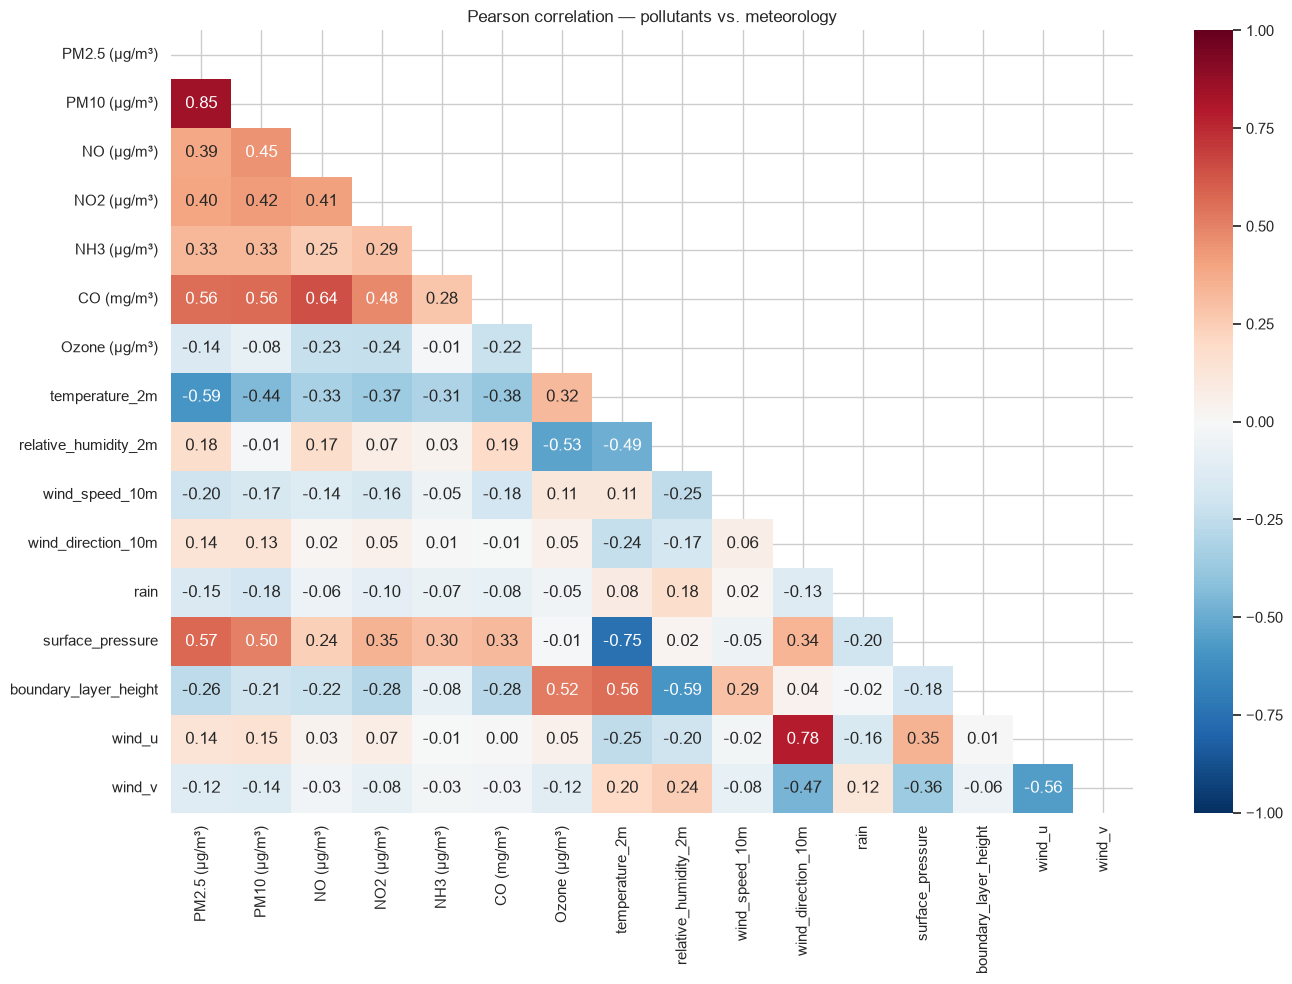

In [13]:
# Cell 10 — Pearson correlation heatmap
num_cols = POLLUTANTS + METEO
corr = df1[num_cols].corr(method="pearson")

plt.figure(figsize=(14, 10))
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, center=0)
plt.title("Pearson correlation — pollutants vs. meteorology")
plt.tight_layout(); plt.show()

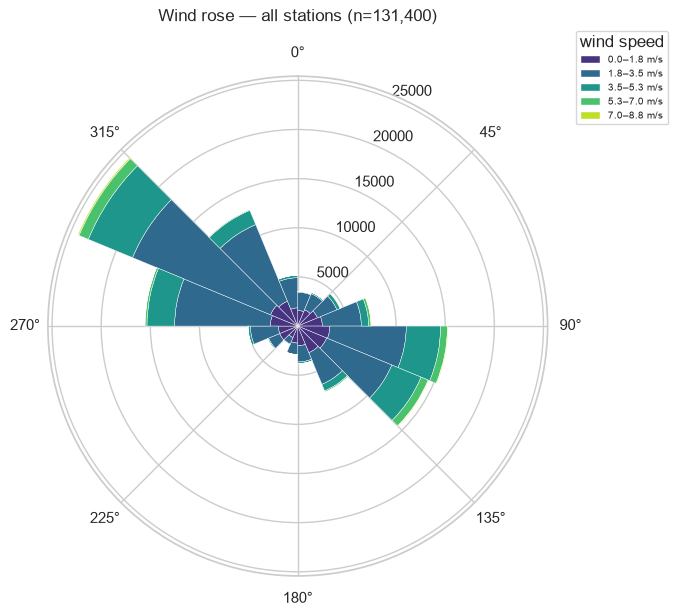

In [33]:
# --- Cell 10a: wind rose (no extra package needed) ---
def draw_wind_rose(ax, directions_deg, speeds, n_dir=16, n_spd=5,
                   title="Wind rose"):
    dir_edges = np.linspace(0, 360, n_dir + 1)
    spd_edges = np.linspace(0, np.nanmax(speeds), n_spd + 1)

    d_idx = np.clip(np.digitize(np.mod(directions_deg, 360), dir_edges) - 1,
                    0, n_dir - 1)
    s_idx = np.clip(np.digitize(speeds, spd_edges) - 1, 0, n_spd - 1)

    # Stacked counts: shape (n_spd, n_dir)
    counts = np.zeros((n_spd, n_dir))
    np.add.at(counts, (s_idx, d_idx), 1)

    theta  = np.deg2rad((dir_edges[:-1] + dir_edges[1:]) / 2)
    width  = np.deg2rad(360 / n_dir)
    colors = plt.cm.viridis(np.linspace(0.15, 0.9, n_spd))

    bottom = np.zeros(n_dir)
    for i in range(n_spd):
        ax.bar(theta, counts[i], width=width, bottom=bottom,
               color=colors[i], edgecolor="white", linewidth=0.3,
               label=f"{spd_edges[i]:.1f}–{spd_edges[i+1]:.1f} m/s")
        bottom += counts[i]

    ax.set_theta_zero_location("N")
    ax.set_theta_direction(-1)
    ax.set_title(title, pad=18)
    ax.legend(title="wind speed", loc="upper right",
              bbox_to_anchor=(1.25, 1.1), fontsize=7)

wr = df1.dropna(subset=["wind_direction_10m", "wind_speed_10m"])
fig = plt.figure(figsize=(7, 7))
ax  = fig.add_subplot(111, polar=True)
draw_wind_rose(ax, wr["wind_direction_10m"].values,
               wr["wind_speed_10m"].values,
               title=f"Wind rose — all stations (n={len(wr):,})")
plt.tight_layout(); plt.show()

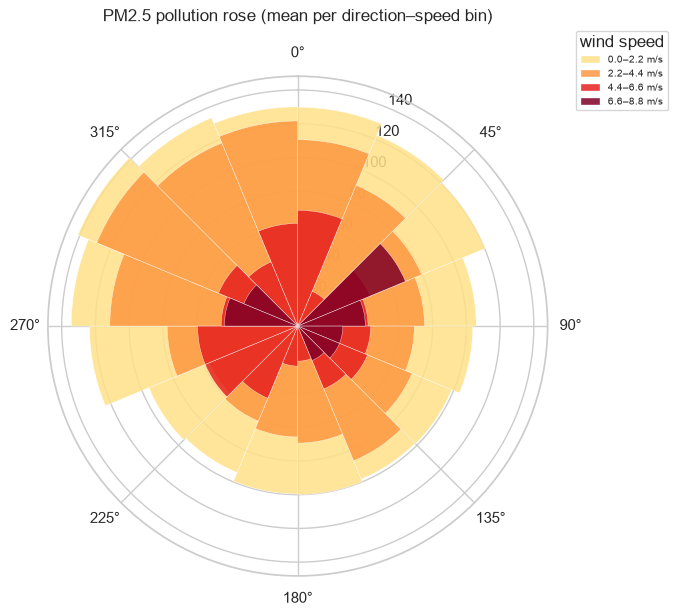

In [34]:
# --- Cell 10b: pollution rose — PM2.5 (mean) by direction × speed bin ---
def draw_pollution_rose(ax, directions_deg, speeds, values,
                        n_dir=16, n_spd=4, title="Pollution rose"):
    dir_edges = np.linspace(0, 360, n_dir + 1)
    spd_edges = np.linspace(0, np.nanmax(speeds), n_spd + 1)

    d_idx = np.clip(np.digitize(np.mod(directions_deg, 360), dir_edges) - 1,
                    0, n_dir - 1)
    s_idx = np.clip(np.digitize(speeds, spd_edges) - 1, 0, n_spd - 1)

    # Mean PM2.5 in each (speed, direction) cell
    vals = np.full((n_spd, n_dir), np.nan)
    for s in range(n_spd):
        for d in range(n_dir):
            m = (s_idx == s) & (d_idx == d)
            if m.any():
                vals[s, d] = np.nanmean(values[m])

    theta  = np.deg2rad((dir_edges[:-1] + dir_edges[1:]) / 2)
    width  = np.deg2rad(360 / n_dir)
    vmax   = np.nanmax(vals)
    colors = plt.cm.YlOrRd(np.linspace(0.2, 1, n_spd))

    for i in range(n_spd):
        heights = np.nan_to_num(vals[i])          # 0 for empty cells
        ax.bar(theta, heights, width=width,
               color=colors[i], alpha=0.85, edgecolor="white",
               linewidth=0.3,
               label=f"{spd_edges[i]:.1f}–{spd_edges[i+1]:.1f} m/s")

    ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
    ax.set_title(title, pad=18)
    ax.legend(title="wind speed", loc="upper right",
              bbox_to_anchor=(1.25, 1.1), fontsize=7)

pr = df1.dropna(subset=["wind_direction_10m", "wind_speed_10m",
                        "PM2.5 (µg/m³)"])
fig = plt.figure(figsize=(7, 7))
ax  = fig.add_subplot(111, polar=True)
draw_pollution_rose(ax, pr["wind_direction_10m"].values,
                    pr["wind_speed_10m"].values,
                    pr["PM2.5 (µg/m³)"].values,
                    title="PM2.5 pollution rose (mean per direction–speed bin)")
plt.tight_layout(); plt.show()

Valid rows per season:
 season
Summer    39608
Autumn    32329
Spring    32240
Winter    20342
Name: count, dtype: int64 



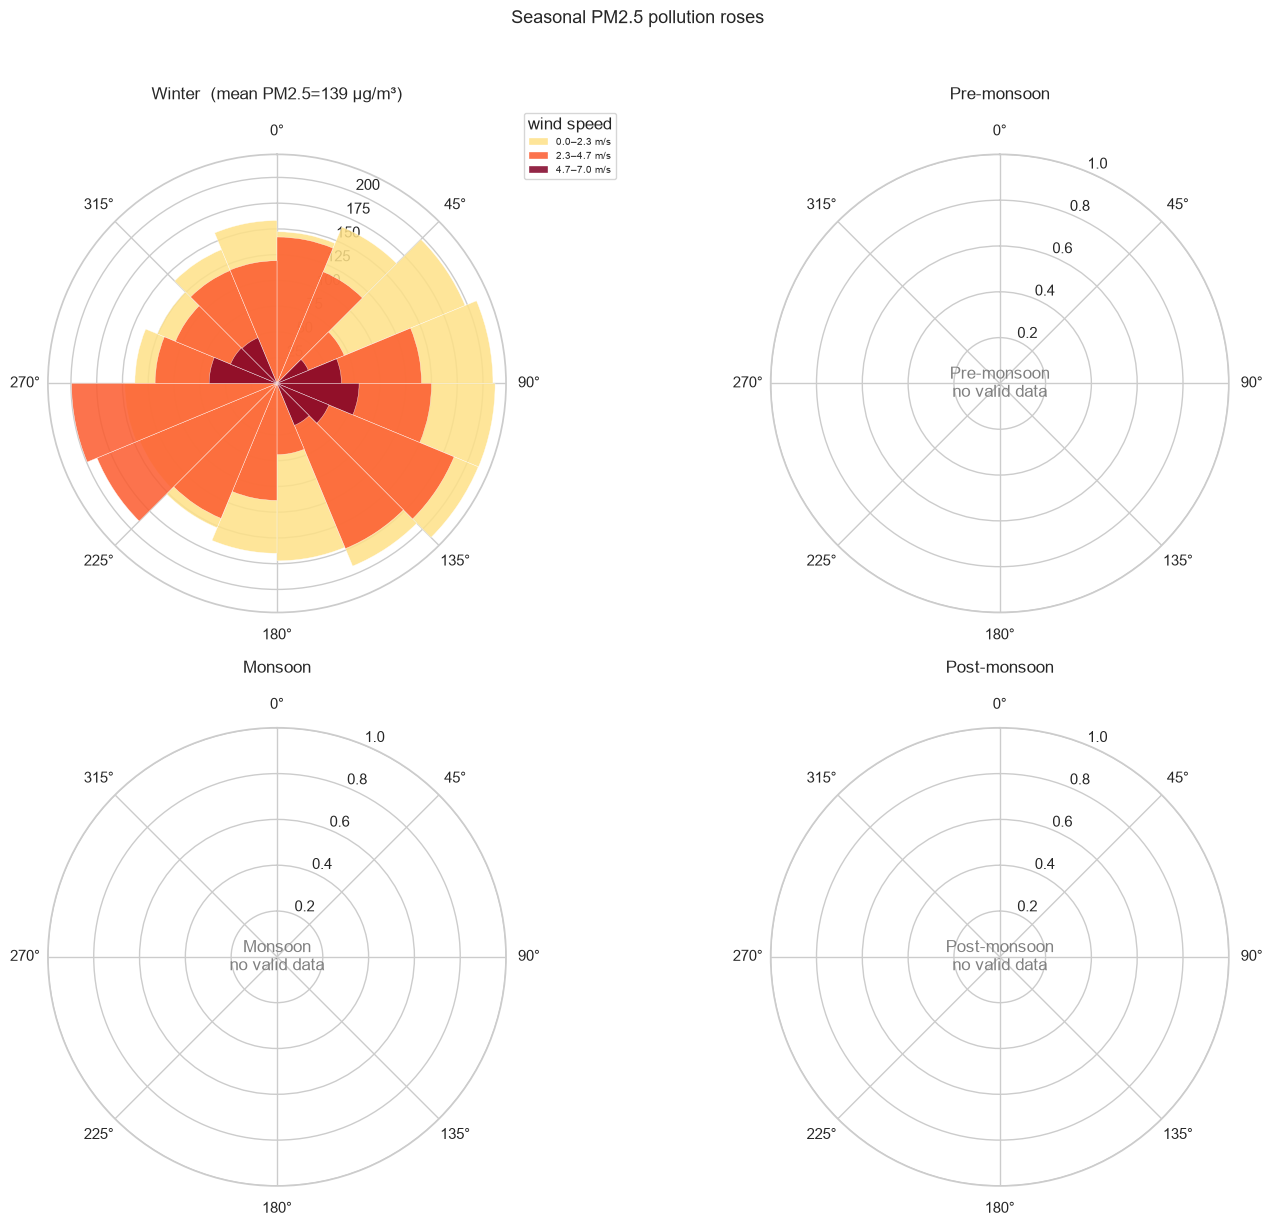

In [39]:
# --- Cell 10c (fixed): seasonal roses — skip empty seasons ---
if "season" not in df1.columns:
    m = df1["timestamp"].dt.month
    df1["season"] = np.select(
        [m.isin([12, 1, 2]), m.isin([3, 4, 5]),
         m.isin([6, 7, 8, 9]), m.isin([10, 11])],
        ["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"],
        default="Other")

SEASONS = ["Winter", "Pre-monsoon", "Monsoon", "Post-monsoon"]

# Pre-filter once so we can report how many rows each season keeps
filtered = df1.dropna(subset=["wind_direction_10m", "wind_speed_10m",
                              "PM2.5 (µg/m³)"])
counts = filtered["season"].value_counts()
print("Valid rows per season:\n", counts, "\n")

fig, axes = plt.subplots(2, 2, subplot_kw={"polar": True}, figsize=(14, 12))
for ax, season in zip(axes.flatten(), SEASONS):
    sub = filtered[filtered["season"] == season]
    if sub.empty:
        ax.text(0.5, 0.5, f"{season}\nno valid data",
                transform=ax.transAxes, ha="center", va="center",
                fontsize=12, color="grey")
        ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
        ax.set_title(season, pad=18)
        continue

    draw_pollution_rose(
        ax,
        sub["wind_direction_10m"].values,
        sub["wind_speed_10m"].values,
        sub["PM2.5 (µg/m³)"].values,
        n_spd=3,
        title=f"{season}  (mean PM2.5={sub['PM2.5 (µg/m³)'].mean():.0f} µg/m³)"
    )

plt.suptitle("Seasonal PM2.5 pollution roses", y=1.02, fontsize=13)
plt.tight_layout(); plt.show()

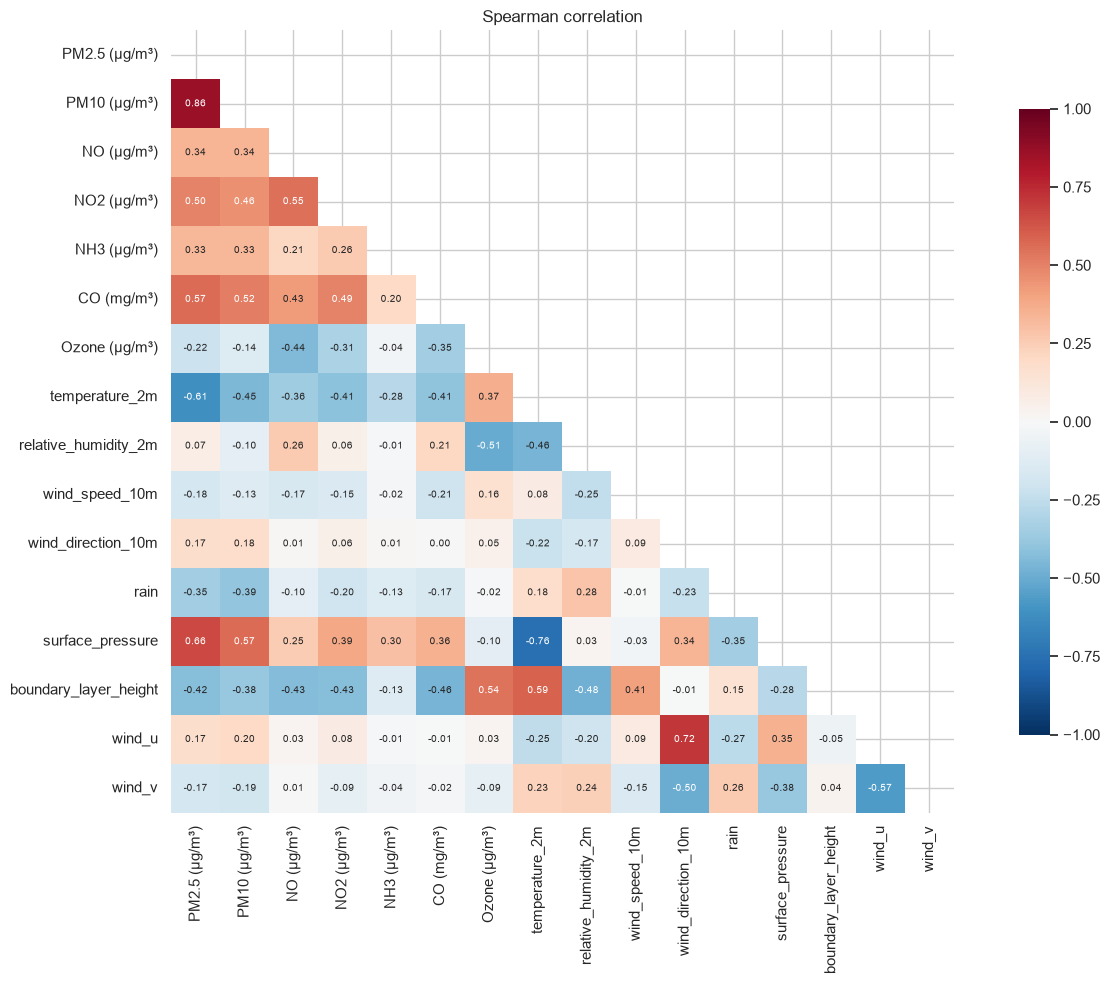

In [14]:
# Cell 11 — Spearman (robust to nonlinear / heavy tails)
corr_s = df1[num_cols].corr(method="spearman")
plt.figure(figsize=(14, 10))
sns.heatmap(corr_s, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r",
            vmin=-1, vmax=1, center=0, square=True,
            cbar_kws={"shrink": 0.8}, annot_kws={"size": 7})
plt.title("Spearman correlation")
plt.tight_layout(); plt.show()

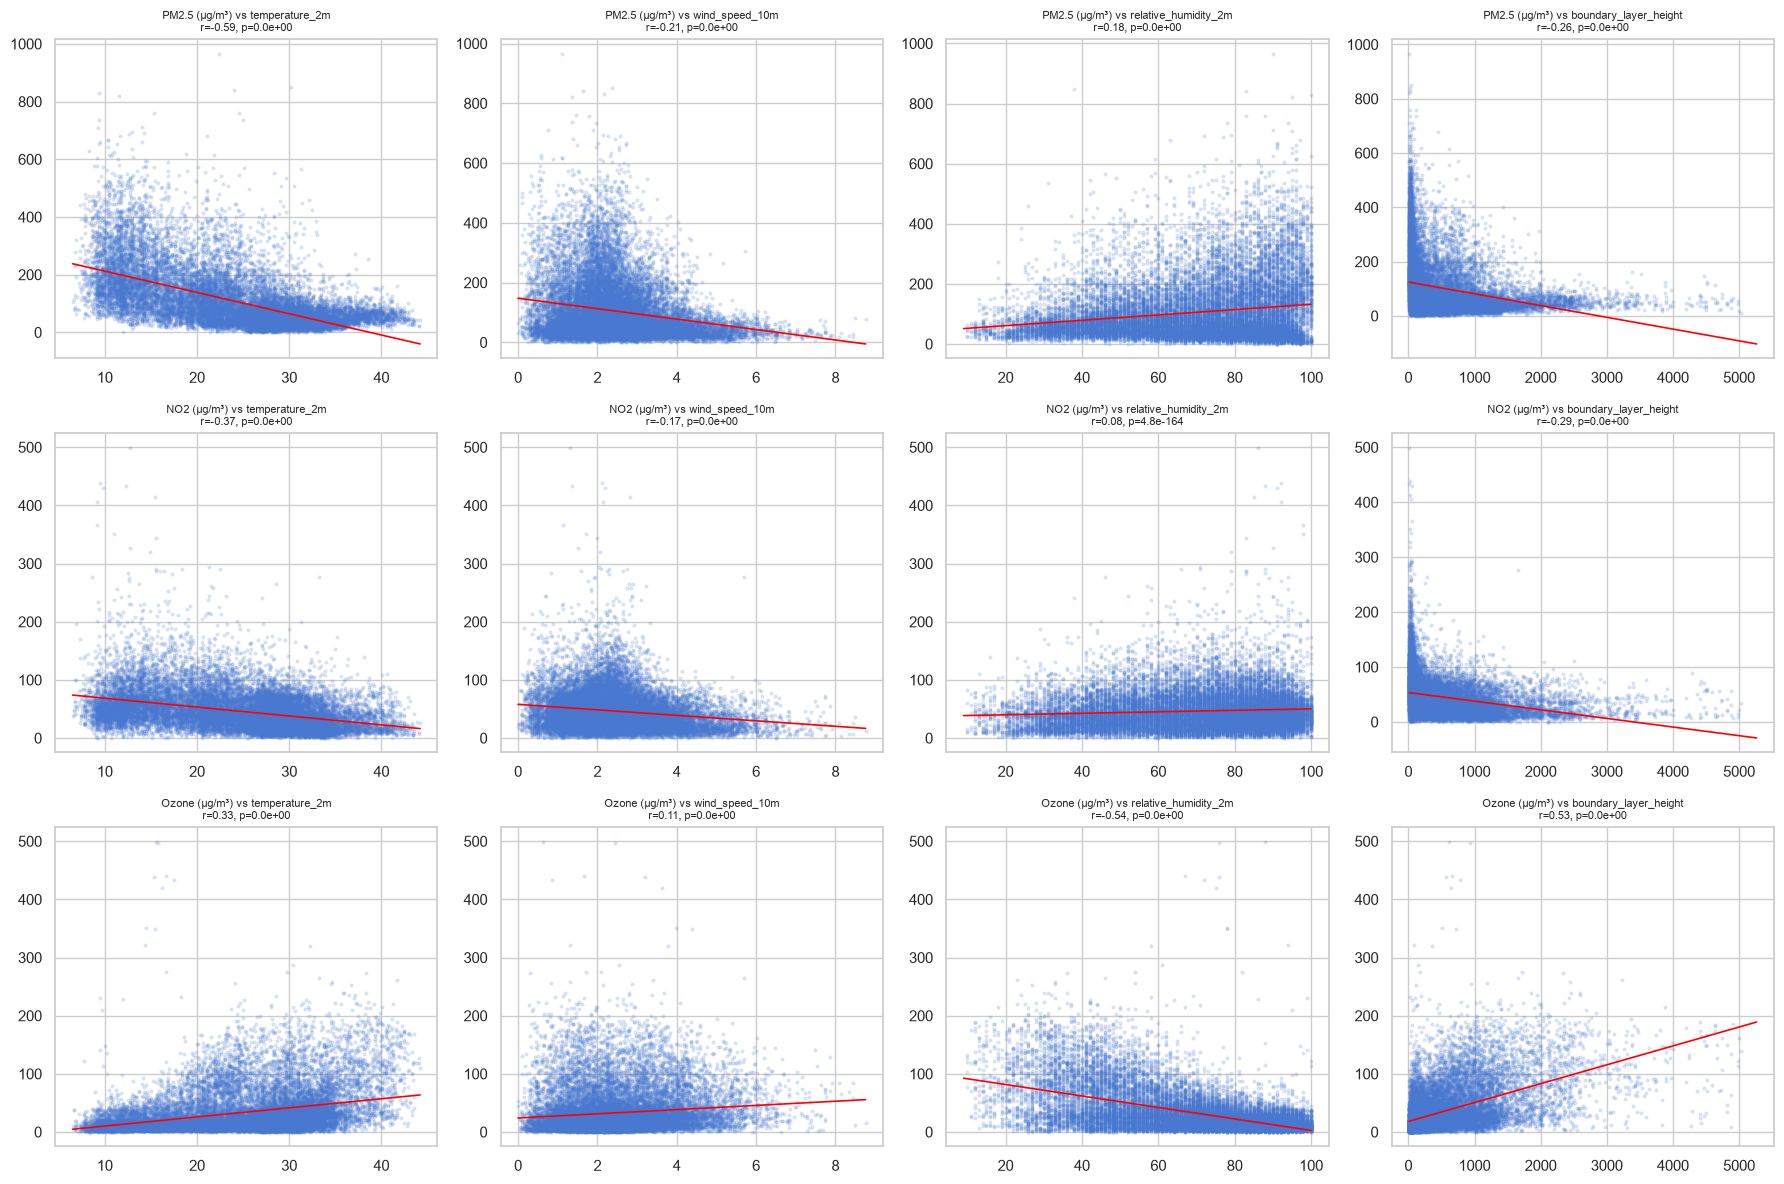

In [17]:
# Cell 12 — Scatter with regression
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import linregress

KEY_METEO = ["temperature_2m", "wind_speed_10m", "relative_humidity_2m",
             "boundary_layer_height"]
KEY_POLL  = ["PM2.5 (µg/m³)", "NO2 (µg/m³)", "Ozone (µg/m³)"]

# 1. Drop NaNs ONCE for all column pairs used below (so r, p, and line all match)
sub = df1[KEY_METEO + KEY_POLL].dropna()
n   = len(sub)

# 2. Subsample for the scatter only — regression stats still use full data
MAX_PTS = 20_000
plot_df = sub.sample(MAX_PTS, random_state=0) if n > MAX_PTS else sub

fig, axes = plt.subplots(len(KEY_POLL), len(KEY_METEO),
                         figsize=(18, 12), sharex=False)

for i, pol in enumerate(KEY_POLL):
    for j, met in enumerate(KEY_METEO):
        ax = axes[i, j]
        x_full = sub[met].to_numpy()
        y_full = sub[pol].to_numpy()

        # 3. Regression + r + p in one C-level call (no bootstrap CI)
        lr = linregress(x_full, y_full)

        # 4. Scatter subsampled + rasterized (cheap to render)
        ax.scatter(plot_df[met], plot_df[pol],
                   s=4, alpha=0.15, rasterized=True)

        # 5. Line as a single Line2D (fast — no regplot machinery)
        xr = np.array([x_full.min(), x_full.max()])
        ax.plot(xr, lr.intercept + lr.slope * xr, color="red", lw=1.2)

        ax.set_title(f"{pol} vs {met}\nr={lr.rvalue:.2f}, p={lr.pvalue:.1e}",
                     fontsize=8)
        ax.set_xlabel(""); ax.set_ylabel("")

plt.tight_layout()
plt.show()

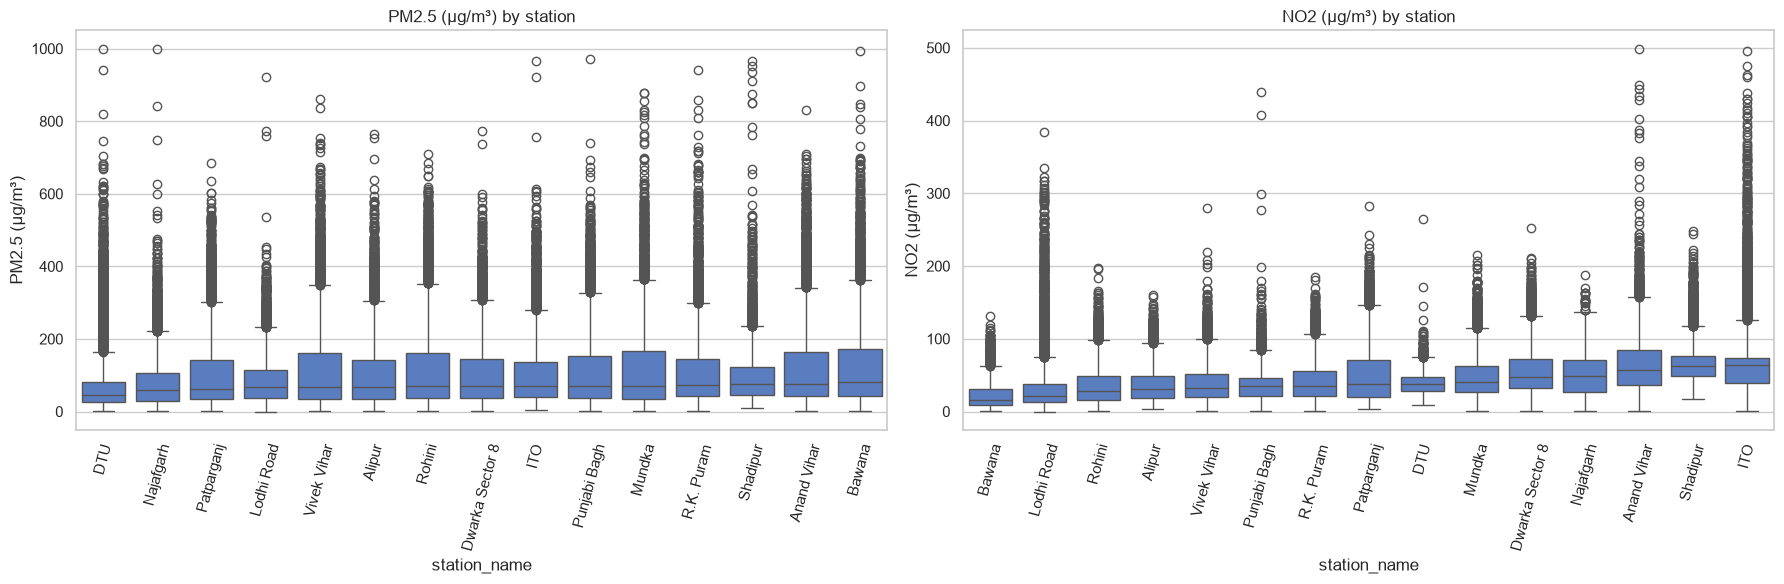

In [18]:
# Cell 13 — Station-wise distribution of PM2.5 & NO2
fig, axes = plt.subplots(1, 2, figsize=(18, 6))
for ax, pol in zip(axes, ["PM2.5 (µg/m³)", "NO2 (µg/m³)"]):
    sns.boxplot(data=df1, x="station_name", y=pol, ax=ax,
                order=df1.groupby("station_name")[pol].median().sort_values().index)
    ax.set_title(f"{pol} by station"); ax.tick_params(axis="x", rotation=75)
plt.tight_layout(); plt.show()

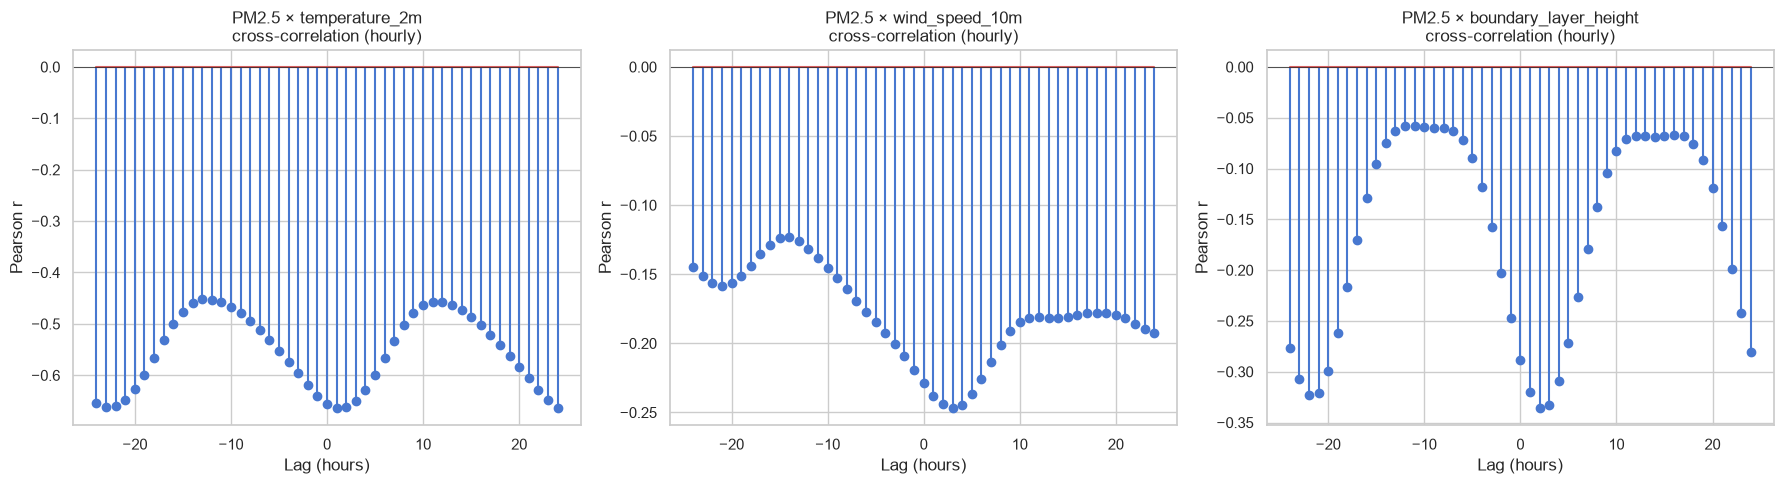

In [19]:
# Cell 14 — Cross-correlation of PM2.5 with key drivers, lags ±24 h
# Aggregate to city-level hourly mean first (avoids station imbalance)
city = (df1.groupby("timestamp")[POLLUTANTS + METEO].mean().sort_index())

def lagged_ccf(series_a, series_b, max_lag=24):
    s = city[[series_a, series_b]].dropna()
    lags = range(-max_lag, max_lag + 1)
    vals = [s[series_a].corr(s[series_b].shift(l)) for l in lags]
    return lags, vals

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, met in zip(axes, ["temperature_2m", "wind_speed_10m",
                          "boundary_layer_height"]):
    lags, vals = lagged_ccf("PM2.5 (µg/m³)", met, max_lag=24)
    ax.stem(list(lags), vals)
    ax.axhline(0, color="k", lw=0.5)
    ax.set_title(f"PM2.5 × {met}\ncross-correlation (hourly)")
    ax.set_xlabel("Lag (hours)"); ax.set_ylabel("Pearson r")
plt.tight_layout(); plt.show()

In [21]:
# Cell 15 — Granger test: does meteo Granger-cause PM2.5?
def granger_report(df, target, driver, max_lag=12):
    s = df[[target, driver]].dropna()
    if len(s) < max_lag * 10:
        return None
    res = grangercausalitytests(s[[target, driver]], maxlag=max_lag)
    # Return min p-value and its lag
    pvals = {lag: res[lag][0]["ssr_ftest"][1] for lag in res}
    best_lag = min(pvals, key=pvals.get)
    return {"driver": driver, "best_lag": best_lag, "min_p": pvals[best_lag]}

rows = [granger_report(city, "PM2.5 (µg/m³)", met) for met in METEO]
pd.DataFrame([r for r in rows if r]).sort_values("min_p")

,driver,best_lag,min_p
0,temperature_2m,12,1.367355e-187
1,relative_humidity_2m,12,7.779038e-175
5,surface_pressure,8,1.792078e-112
6,boundary_layer_height,1,9.257632e-88
8,wind_v,3,8.159858e-14
3,wind_direction_10m,12,2.559003e-13
2,wind_speed_10m,5,1.256983e-12
7,wind_u,6,2.192258e-11
4,rain,2,1.104118e-02


In [22]:
# Cell 16 — ADF test on PM2.5 levels and first difference
for col in ["PM2.5 (µg/m³)", "temperature_2m"]:
    s = city[col].dropna()
    p_level = adfuller(s)[1]
    p_diff  = adfuller(s.diff().dropna())[1]
    print(f"{col:25s}  ADF p (level)={p_level:.3f}   ADF p (diff)={p_diff:.3f}")

C:\Users\HP\AppData\Local\Temp\ipykernel_1440\2250772936.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_level = adfuller(s)[1]
C:\Users\HP\AppData\Local\Temp\ipykernel_1440\2250772936.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_diff  = adfuller(s.diff().dropna())[1]


PM2.5 (µg/m³)              ADF p (level)=0.000   ADF p (diff)=0.000


C:\Users\HP\AppData\Local\Temp\ipykernel_1440\2250772936.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_level = adfuller(s)[1]


temperature_2m             ADF p (level)=0.223   ADF p (diff)=0.000


C:\Users\HP\AppData\Local\Temp\ipykernel_1440\2250772936.py:5: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  p_diff  = adfuller(s.diff().dropna())[1]


C:\Users\HP\AppData\Local\Temp\ipykernel_1440\477203884.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for season, sub in df1.groupby("season"):


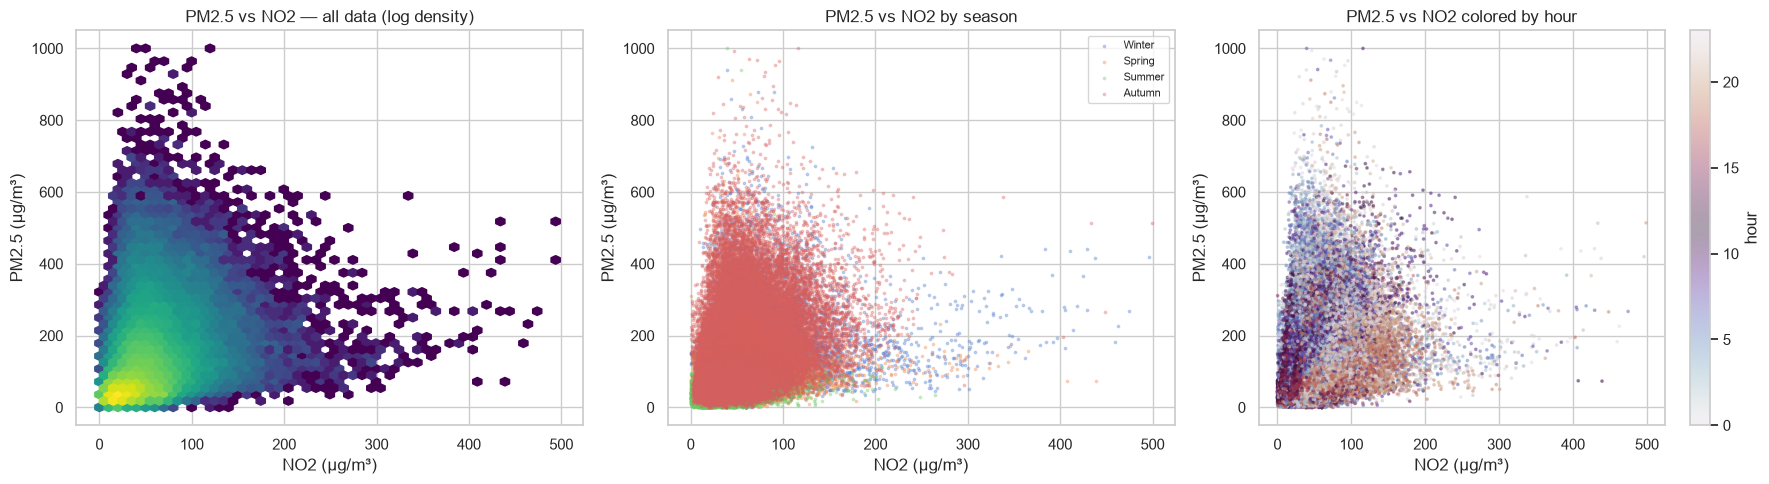

In [23]:
# Cell 17 — Hexbin joint distributions
df1["hour"]  = df1["timestamp"].dt.hour
df1["month"] = df1["timestamp"].dt.month
df1["season"] = pd.cut(df1["month"], bins=[0,2,5,9,12],
                       labels=["Winter","Spring","Summer","Autumn"])

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
# By hour
hb = axes[0].hexbin(df1["NO2 (µg/m³)"], df1["PM2.5 (µg/m³)"],
                    gridsize=50, cmap="viridis", bins="log")
axes[0].set_title("PM2.5 vs NO2 — all data (log density)")
# By season (scatter overlay, sample)
for season, sub in df1.groupby("season"):
    axes[1].scatter(sub["NO2 (µg/m³)"], sub["PM2.5 (µg/m³)"],
                    s=3, alpha=0.3, label=season)
axes[1].set_title("PM2.5 vs NO2 by season"); axes[1].legend(fontsize=8)
# By hour color
sc = axes[2].scatter(df1["NO2 (µg/m³)"], df1["PM2.5 (µg/m³)"],
                     c=df1["hour"], cmap="twilight", s=3, alpha=0.4)
plt.colorbar(sc, ax=axes[2], label="hour")
axes[2].set_title("PM2.5 vs NO2 colored by hour")
for ax in axes: ax.set_xlabel("NO2 (µg/m³)"); ax.set_ylabel("PM2.5 (µg/m³)")
plt.tight_layout(); plt.show()

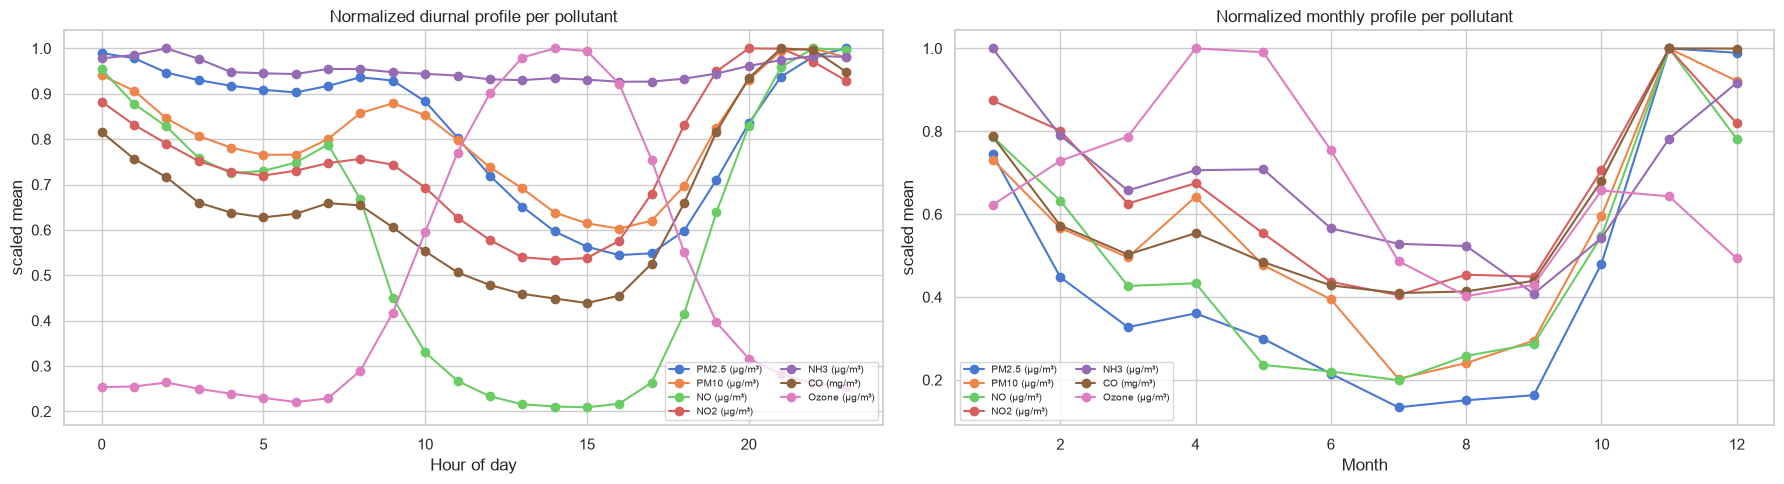

In [24]:
# Cell 18 — Hourly and monthly pollution profiles (multivariate line plots)
hourly = df1.groupby("hour")[POLLUTANTS].mean()
monthly = df1.groupby("month")[POLLUTANTS].mean()

# Normalize each pollutant to its max for comparable scale
fig, axes = plt.subplots(1, 2, figsize=(18, 5))
(hourly / hourly.max()).plot(ax=axes[0], marker="o")
axes[0].set_title("Normalized diurnal profile per pollutant")
axes[0].set_xlabel("Hour of day"); axes[0].set_ylabel("scaled mean")
axes[0].legend(fontsize=7, ncol=2)

(monthly / monthly.max()).plot(ax=axes[1], marker="o")
axes[1].set_title("Normalized monthly profile per pollutant")
axes[1].set_xlabel("Month"); axes[1].set_ylabel("scaled mean")
axes[1].legend(fontsize=7, ncol=2)
plt.tight_layout(); plt.show()

In [25]:
# Cell 19 — PCA on standardized pollutants
X = df1[POLLUTANTS].dropna()
Xs = StandardScaler().fit_transform(X)

pca = PCA(n_components=len(POLLUTANTS))
scores = pca.fit_transform(Xs)

print("Explained variance ratio:")
for i, v in enumerate(pca.explained_variance_ratio_):
    print(f"  PC{i+1}: {v:.3f}  (cumulative {pca.explained_variance_ratio_[:i+1].sum():.3f})")

# Loadings
loadings = pd.DataFrame(pca.components_.T,
                        index=POLLUTANTS,
                        columns=[f"PC{i+1}" for i in range(len(POLLUTANTS))])
print("\nLoadings (first 3 PCs):")
print(loadings.iloc[:, :3].round(2))

Explained variance ratio:
  PC1: 0.484  (cumulative 0.484)
  PC2: 0.153  (cumulative 0.637)
  PC3: 0.112  (cumulative 0.749)
  PC4: 0.103  (cumulative 0.851)
  PC5: 0.085  (cumulative 0.936)
  PC6: 0.044  (cumulative 0.980)
  PC7: 0.020  (cumulative 1.000)

Loadings (first 3 PCs):
                PC1   PC2   PC3
PM2.5 (µg/m³)  0.44  0.24 -0.36
PM10 (µg/m³)   0.45  0.27 -0.35
NO (µg/m³)     0.39 -0.22  0.05
NO2 (µg/m³)    0.37 -0.16  0.23
NH3 (µg/m³)    0.27  0.39  0.82
CO (mg/m³)     0.45 -0.14 -0.06
Ozone (µg/m³) -0.16  0.79 -0.12


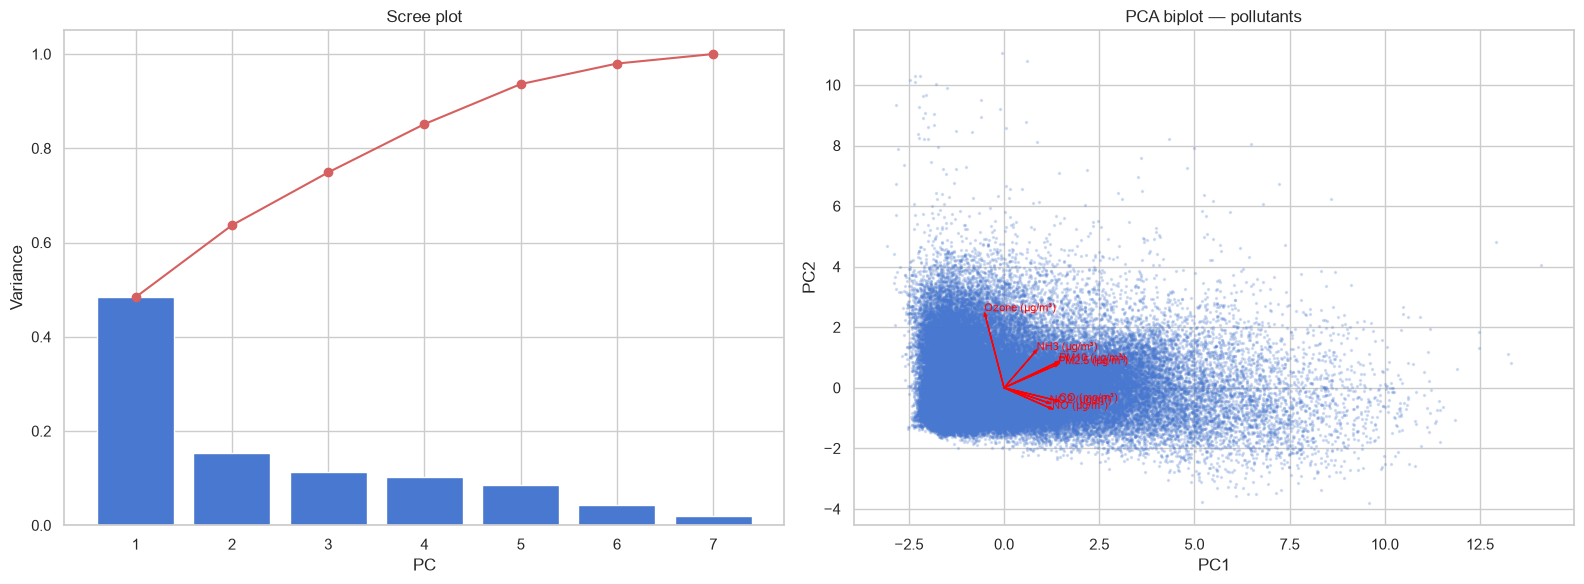

In [26]:
# Cell 20 — Biplot + scree
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Scree
axes[0].bar(range(1, len(pca.explained_variance_ratio_)+1),
            pca.explained_variance_ratio_)
axes[0].plot(range(1, len(pca.explained_variance_ratio_)+1),
             np.cumsum(pca.explained_variance_ratio_), "r-o")
axes[0].set_title("Scree plot"); axes[0].set_xlabel("PC"); axes[0].set_ylabel("Variance")

# Biplot (PC1 vs PC2)
axes[1].scatter(scores[:, 0], scores[:, 1], s=2, alpha=0.2)
for i, p in enumerate(POLLUTANTS):
    axes[1].arrow(0, 0,
                  pca.components_[0, i] * 3,
                  pca.components_[1, i] * 3,
                  color="red", head_width=0.08)
    axes[1].text(pca.components_[0, i] * 3.2,
                 pca.components_[1, i] * 3.2, p, fontsize=8, color="red")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].set_title("PCA biplot — pollutants")
plt.tight_layout(); plt.show()

In [27]:
# Cell 21 — OLS-style regression (statsmodels)
import statsmodels.api as sm

reg_df = city.dropna(subset=["PM2.5 (µg/m³)"])
X = reg_df[["temperature_2m", "wind_speed_10m", "relative_humidity_2m",
            "boundary_layer_height", "NO2 (µg/m³)", "CO (mg/m³)",
            "Ozone (µg/m³)"]]
X = sm.add_constant(X)
y = reg_df["PM2.5 (µg/m³)"]

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:          PM2.5 (µg/m³)   R-squared:                       0.711
Model:                            OLS   Adj. R-squared:                  0.711
Method:                 Least Squares   F-statistic:                     3075.
Date:                Sun, 25 Oct 2026   Prob (F-statistic):               0.00
Time:                        10:20:36   Log-Likelihood:                -46291.
No. Observations:                8760   AIC:                         9.260e+04
Df Residuals:                    8752   BIC:                         9.265e+04
Df Model:                           7                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                   157.21

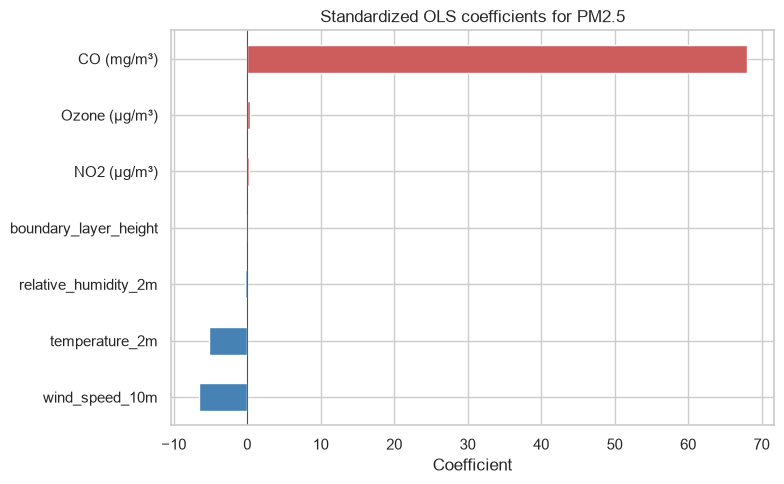

In [28]:
# Cell 22 — Coefficient plot
coefs = model.params.drop("const").sort_values()
plt.figure(figsize=(8, 5))
coefs.plot(kind="barh", color=np.where(coefs < 0, "steelblue", "indianred"))
plt.axvline(0, color="k", lw=0.5)
plt.title("Standardized OLS coefficients for PM2.5")
plt.xlabel("Coefficient"); plt.tight_layout(); plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_1440\1507819622.py:25: UserWarning: Glyph 8733 (\N{PROPORTIONAL TO}) missing from font(s) Arial.
  plt.tight_layout(); plt.show()
d:\miniproject\.venv\Lib\site-packages\IPython\core\pylabtools.py:158: UserWarning: Glyph 8733 (\N{PROPORTIONAL TO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


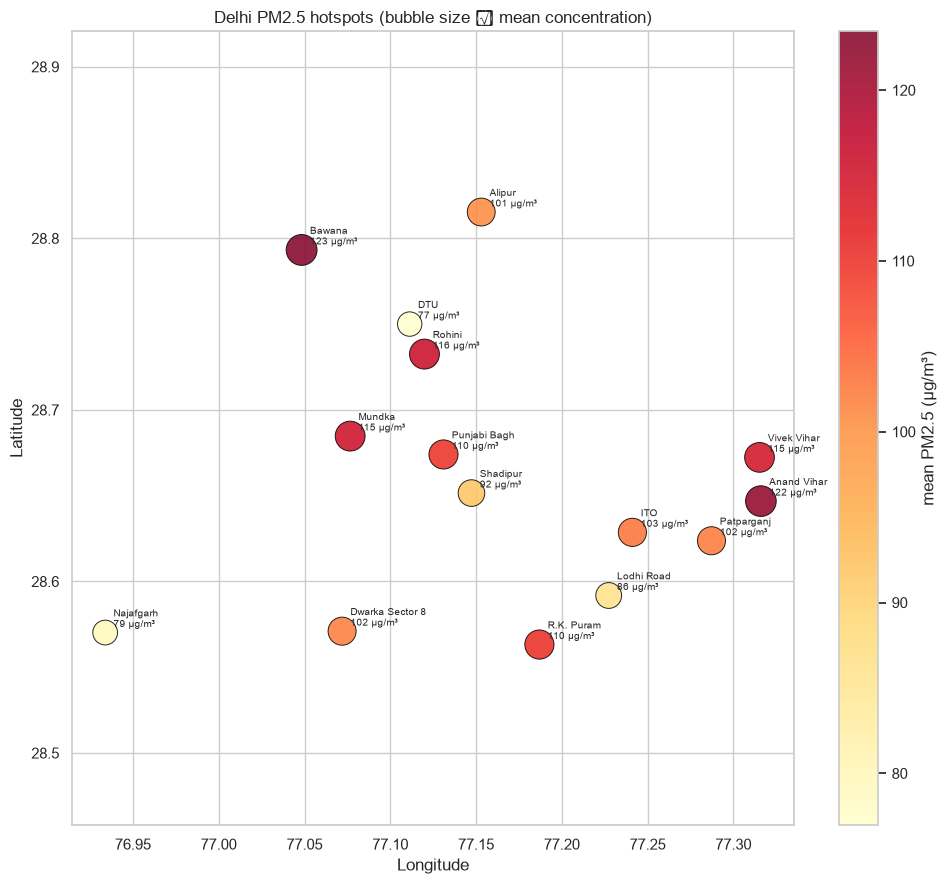

In [36]:
# --- Cell 22: spatial hotspot map of mean PM2.5 ---
# Uses latitude_x / longitude_x (station coordinates)
st = (df1.groupby("station_name")
         .agg(lat=("latitude_x", "first"),
              lon=("longitude_x", "first"),
              pm25=("PM2.5 (µg/m³)", "mean"),
              no2=("NO2 (µg/m³)", "mean"),
              n=("PM2.5 (µg/m³)", "count"))
         .reset_index())

fig, ax = plt.subplots(figsize=(10, 9))
sc = ax.scatter(st["lon"], st["lat"], s=st["pm25"] * 4,
                c=st["pm25"], cmap="YlOrRd", edgecolor="black",
                linewidth=0.7, alpha=0.85, vmin=st["pm25"].min())

for _, row in st.iterrows():
    ax.annotate(f"{row.station_name}\n{row.pm25:.0f} µg/m³",
                (row.lon, row.lat), xytext=(6, 4),
                textcoords="offset points", fontsize=7)

plt.colorbar(sc, ax=ax, label="mean PM2.5 (µg/m³)")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
ax.set_title("Delhi PM2.5 hotspots (bubble size ∝ mean concentration)")
ax.set_aspect("equal", adjustable="datalim")
plt.tight_layout(); plt.show()

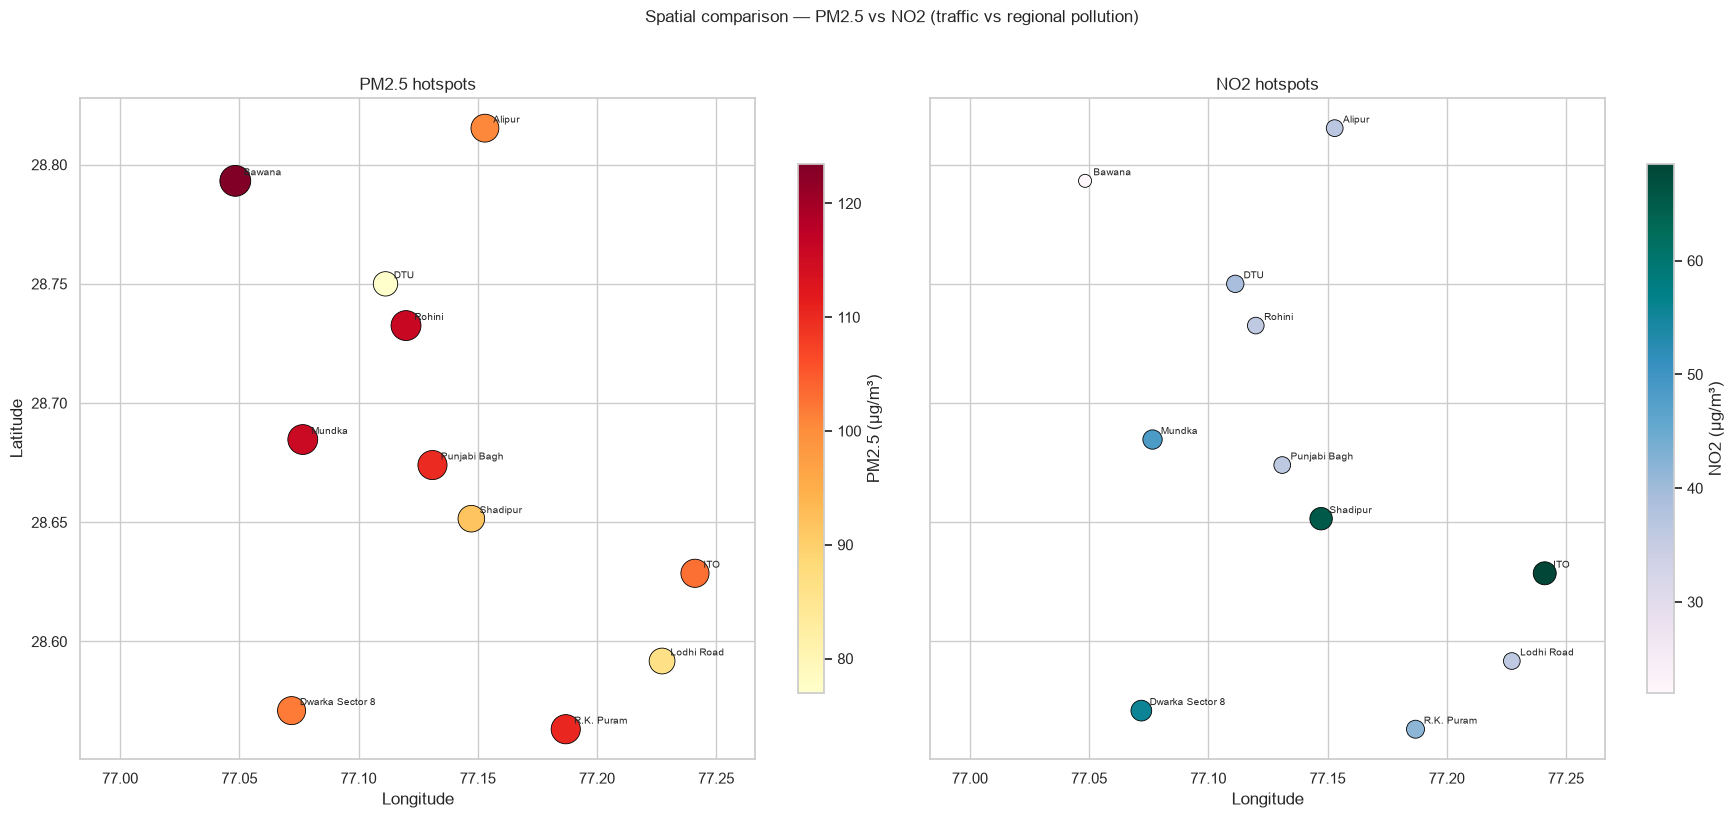

Spatial PM2.5 vs NO2 across stations: r = -0.159, p = 0.572


In [37]:
# --- Cell 23: joint spatial map — PM2.5 vs NO2 ---
fig, axes = plt.subplots(1, 2, figsize=(18, 8), sharey=True)

# Panel 1 — PM2.5
sc1 = axes[0].scatter(st["lon"], st["lat"], s=st["pm25"] * 4,
                      c=st["pm25"], cmap="YlOrRd",
                      edgecolor="black", linewidth=0.6)
plt.colorbar(sc1, ax=axes[0], label="PM2.5 (µg/m³)", shrink=0.8)
axes[0].set_title("PM2.5 hotspots")

# Panel 2 — NO2
sc2 = axes[1].scatter(st["lon"], st["lat"], s=st["no2"] * 4,
                      c=st["no2"], cmap="PuBuGn",
                      edgecolor="black", linewidth=0.6)
plt.colorbar(sc2, ax=axes[1], label="NO2 (µg/m³)", shrink=0.8)
axes[1].set_title("NO2 hotspots")

for ax in axes:
    for _, row in st.iterrows():
        ax.annotate(row.station_name, (row.lon, row.lat),
                    xytext=(6, 4), textcoords="offset points", fontsize=7)
    ax.set_xlabel("Longitude"); ax.set_aspect("equal", adjustable="datalim")
axes[0].set_ylabel("Latitude")
plt.suptitle("Spatial comparison — PM2.5 vs NO2 (traffic vs regional pollution)",
             y=1.02, fontsize=12)
plt.tight_layout(); plt.show()

# Quick spatial correlation between the two pollutant fields
r_spatial, p_spatial = pearsonr(st["pm25"], st["no2"])
print(f"Spatial PM2.5 vs NO2 across stations: r = {r_spatial:.3f}, "
      f"p = {p_spatial:.3f}")

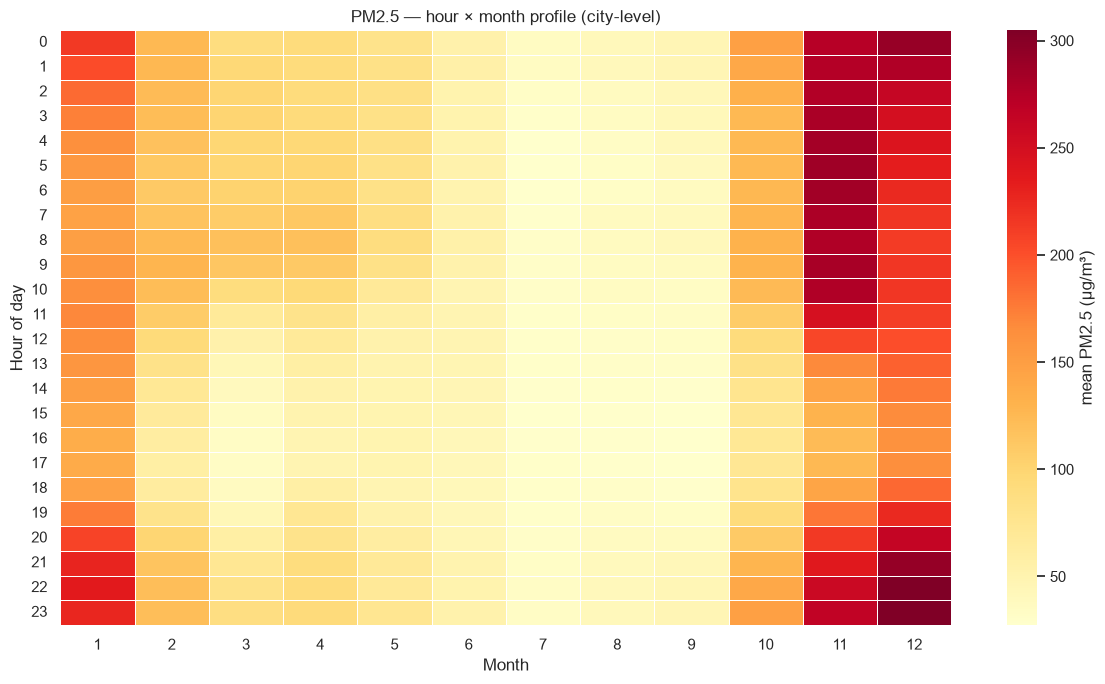

In [38]:
# --- Cell 24: hour × month heatmap of mean PM2.5 (city-level) ---
# Use city-level means to avoid station coverage bias
city_pm = (df1.groupby(["timestamp"])["PM2.5 (µg/m³)"].mean()
           .to_frame("pm25").dropna().reset_index())
city_pm["hour"]  = city_pm["timestamp"].dt.hour
city_pm["month"] = city_pm["timestamp"].dt.month

pivot = city_pm.pivot_table(index="hour", columns="month",
                            values="pm25", aggfunc="mean")

fig, ax = plt.subplots(figsize=(12, 7))
sns.heatmap(pivot, cmap="YlOrRd", ax=ax,
            cbar_kws={"label": "mean PM2.5 (µg/m³)"},
            linewidths=0.4, linecolor="white")
ax.set_ylabel("Hour of day"); ax.set_xlabel("Month")
ax.set_title("PM2.5 — hour × month profile (city-level)")
ax.set_yticklabels(ax.get_yticklabels(), rotation=0)
plt.tight_layout(); plt.show()

In [29]:
# Cell 23 — KMeans on station pollutant profiles
station_profile = df1.groupby("station_name")[POLLUTANTS].mean()
Z = StandardScaler().fit_transform(station_profile)

km = KMeans(n_clusters=3, random_state=RANDOM_STATE, n_init=10).fit(Z)
station_profile["cluster"] = km.labels_

plt.figure(figsize=(8, 6))
sns.heatmap(station_profile[POLLUTANTS].T,
            cmap="YlOrRd", annot=True, fmt=".0f",
            cbar_kws={"label": "mean concentration"})
plt.title("Station pollutant profiles (sorted by cluster)\n"
          f"(cluster labels shown below)")
plt.ylabel("Pollutant")
# Show cluster on x-axis
ax = plt.gca()
ax.set_xticklabels([f"{s} [c{c}]" for s, c in
                    zip(station_profile.index, station_profile["cluster"])],
                   rotation=75, fontsize=8)
plt.tight_layout(); plt.show()

ValueError: Input X contains NaN.
KMeans does not accept missing values encoded as NaN natively. For supervised learning, you might want to consider sklearn.ensemble.HistGradientBoostingClassifier and Regressor which accept missing values encoded as NaNs natively. Alternatively, it is possible to preprocess the data, for instance by using an imputer transformer in a pipeline or drop samples with missing values. See https://scikit-learn.org/stable/modules/impute.html You can find a list of all estimators that handle NaN values at the following page: https://scikit-learn.org/stable/modules/impute.html#estimators-that-handle-nan-values

C:\Users\HP\AppData\Local\Temp\ipykernel_1440\3130957305.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  wdf["wd_bin"] = (wdf["wind_direction_10m"] // 22.5) * 22.5  # 16 bins


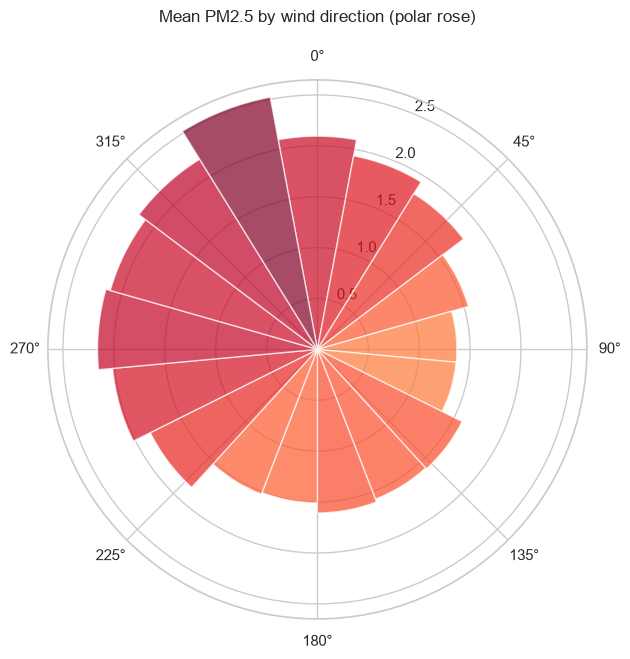

In [30]:
# Cell 24 — Polar plot: mean PM2.5 by wind direction bin
wdf = df1.dropna(subset=["PM2.5 (µg/m³)", "wind_direction_10m"])
wdf["wd_bin"] = (wdf["wind_direction_10m"] // 22.5) * 22.5  # 16 bins
rad = np.deg2rad(wdf.groupby("wd_bin")["PM2.5 (µg/m³)"].mean())

fig = plt.figure(figsize=(7, 7))
ax = plt.subplot(111, polar=True)
theta = np.linspace(0, 2*np.pi, len(rad), endpoint=False)
ax.bar(theta, rad.values, width=2*np.pi/len(rad), alpha=0.7,
       color=plt.cm.YlOrRd(rad.values / rad.values.max()))
ax.set_theta_zero_location("N"); ax.set_theta_direction(-1)
ax.set_title("Mean PM2.5 by wind direction (polar rose)", pad=20)
plt.show()

In [31]:
# Cell 25 — Summary template
summary = {
    "rows": len(df1),
    "stations": df1["station_name"].nunique(),
    "time_span": (df1["timestamp"].min(), df1["timestamp"].max()),
    "top_PM2.5_station": df1.groupby("station_name")["PM2.5 (µg/m³)"].mean().idxmax(),
    "strongest_neg_corr_PM25": corr.loc["PM2.5 (µg/m³)"].drop("PM2.5 (µg/m³)").idxmin(),
    "strongest_pos_corr_PM25": corr.loc["PM2.5 (µg/m³)"].drop("PM2.5 (µg/m³)").idxmax(),
    "PC1_variance": round(pca.explained_variance_ratio_[0], 3),
}
for k, v in summary.items():
    print(f"{k:30s}: {v}")

rows                          : 131400
stations                      : 15
time_span                     : (Timestamp('2025-01-01 00:00:00'), Timestamp('2025-12-31 23:00:00'))
top_PM2.5_station             : Bawana
strongest_neg_corr_PM25       : temperature_2m
strongest_pos_corr_PM25       : PM10 (µg/m³)
PC1_variance                  : 0.484
